# Assignment 3 - Sequence Models with RNNs, LSTMs, and Transformers

This notebook follows the assignment brief from top to bottom and is designed to be run with **Runtime > Run all**. In Google Colab it uses a GPU and persists caches, checkpoints, results, and figures to Google Drive by default; the first run may display Google's standard Drive authorization prompt. Outside Colab it uses the local `assignment3_artifacts/` directory instead. Completed experiments are detected and skipped, so an interrupted run can be resumed safely.

## 1. Setup and reproducibility


In [ ]:
# Install packages that are not guaranteed to exist in a fresh Colab runtime.
%pip install -q datasets transformers accelerate scikit-learn pandas matplotlib seaborn joblib ipywidgets

In [ ]:
from __future__ import annotations

import html
import json
import math
import random
import re
import subprocess
import time
import unicodedata
import warnings
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any, Callable, Sequence

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from IPython.display import HTML, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    log_loss,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from torch.nn.utils import clip_grad_norm_
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, Dataset, TensorDataset
from tqdm import TqdmWarning
from transformers import (
    AutoModel,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)

# Hide expected third-party warnings so experimental output stays readable.
warnings.filterwarnings("ignore", category=TqdmWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings(
    "ignore",
    message="enable_nested_tensor is True.*",
    category=UserWarning,
)
sns.set_theme(style="whitegrid")

# The brief recommends Drive because Colab runtimes can disconnect. Local
# Jupyter always uses the repository-local fallback.
def is_colab_runtime() -> bool:
    """Detect Colab without importing Colab-only modules locally."""
    shell = get_ipython() if "get_ipython" in globals() else None
    return (
        shell is not None
        and type(shell).__module__.startswith("google.colab")
    )


IN_COLAB = is_colab_runtime()
USE_GOOGLE_DRIVE = True
GOOGLE_DRIVE_ARTIFACT_ROOT = Path(
    "/content/drive/MyDrive/DEEP001/Assignment_3"
)
LOCAL_ARTIFACT_ROOT = Path.cwd() / "assignment3_artifacts"


def configure_artifact_root() -> Path:
    """Return persistent Colab storage or the local fallback."""
    if not (IN_COLAB and USE_GOOGLE_DRIVE):
        return LOCAL_ARTIFACT_ROOT

    from google.colab import drive

    drive.mount("/content/drive")
    return GOOGLE_DRIVE_ARTIFACT_ROOT


ARTIFACT_ROOT = configure_artifact_root()

CACHE_DIR = ARTIFACT_ROOT / "cache"
CHECKPOINT_DIR = ARTIFACT_ROOT / "checkpoints"
RESULTS_DIR = ARTIFACT_ROOT / "results"
FIGURE_DIR = ARTIFACT_ROOT / "figures"
for directory in (CACHE_DIR, CHECKPOINT_DIR, RESULTS_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
if IN_COLAB and DEVICE.type != "cuda":
    raise RuntimeError(
        "No Colab GPU is attached. Select Runtime > Change runtime type > "
        "T4 GPU, reconnect, and run the notebook again."
    )

print(f"Execution environment: {'Google Colab' if IN_COLAB else 'local'}")
print(f"Device: {DEVICE}")
if DEVICE.type == "cuda":
    subprocess.run(["nvidia-smi"], check=False)

SEED = 2026


def set_seed(seed: int, deterministic: bool = False) -> None:
    """Seed Python, NumPy, and PyTorch for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic


def count_trainable(model: nn.Module) -> int:
    """Count parameters that receive gradient updates."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def count_total(model: nn.Module) -> int:
    """Count every parameter in a model."""
    return sum(p.numel() for p in model.parameters())


def cuda_sync() -> None:
    """Synchronize CUDA before timing GPU work."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def read_jsonl(path: Path) -> list[dict[str, Any]]:
    """Load newline-delimited experiment records."""
    if not path.exists():
        return []
    rows = []
    with path.open(encoding="utf-8") as stream:
        for line in stream:
            if line.strip():
                rows.append(json.loads(line))
    return rows


def upsert_jsonl(
    path: Path,
    row: dict[str, Any],
    key_fields: Sequence[str],
) -> None:
    """Insert a record, replacing one with the same experiment key."""
    row_key = tuple(row[field] for field in key_fields)
    rows = [
        existing
        for existing in read_jsonl(path)
        if tuple(existing[field] for field in key_fields) != row_key
    ]
    rows.append(row)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as stream:
        for record in rows:
            stream.write(json.dumps(record, default=float) + "\n")


def save_json(path: Path, value: Any) -> None:
    """Serialize a JSON-compatible value with readable indentation."""
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as stream:
        json.dump(value, stream, indent=2, default=float)


def load_json(path: Path, default: Any = None) -> Any:
    """Load JSON or return the supplied default when absent."""
    if not path.exists():
        return default
    with path.open(encoding="utf-8") as stream:
        return json.load(stream)


def to_device(batch: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    """Move every tensor in a batch to the selected device."""
    return {key: value.to(DEVICE) for key, value in batch.items()}


set_seed(SEED)
print(f"Artifacts: {ARTIFACT_ROOT}")


## 2. Part A - Delayed-recall task


In [ ]:
# Part A data generation
V = 10
LENGTHS = [5, 10, 20, 50, 100, 200]
N_EPOCH, N_EVAL = 20_000, 2_000


def make_recall(n: int, T: int, seed: int) -> tuple[torch.Tensor, torch.Tensor]:
    """Generate n sequences of T random digits; the label is the first digit."""
    generator = torch.Generator().manual_seed(seed)
    x = torch.randint(0, V, (n, T), generator=generator)
    return x, x[:, 0].clone()


def training_set(T: int, epoch: int) -> tuple[torch.Tensor, torch.Tensor]:
    """Generate a fresh deterministic training set for one epoch."""
    return make_recall(N_EPOCH, T, seed=100_000 * T + epoch)


recall_val = {T: make_recall(N_EVAL, T, seed=10 * T + 1) for T in LENGTHS}
recall_test = {T: make_recall(N_EVAL, T, seed=10 * T + 2) for T in LENGTHS}


In [ ]:
# Part A model definitions and parameter-count verification
def sinusoidal_encoding(max_length: int, width: int) -> torch.Tensor:
    """Construct fixed sinusoidal positional encodings."""
    positions = torch.arange(max_length, dtype=torch.float32).unsqueeze(1)
    frequencies = torch.exp(
        torch.arange(0, width, 2, dtype=torch.float32)
        * (-math.log(10_000.0) / width)
    )
    encoding = torch.zeros(max_length, width)
    encoding[:, 0::2] = torch.sin(positions * frequencies)
    encoding[:, 1::2] = torch.cos(positions * frequencies)
    return encoding


class RecallRNN(nn.Module):
    """Vanilla RNN baseline for predicting the first digit."""

    def __init__(self) -> None:
        super().__init__()
        self.emb = nn.Embedding(10, 32)
        self.rnn = nn.RNN(32, 128, nonlinearity="tanh", batch_first=True)
        self.classifier = nn.Linear(128, 10)

    def forward_from_embeddings(self, embeddings: torch.Tensor) -> torch.Tensor:
        _, hidden = self.rnn(embeddings)
        return self.classifier(hidden[-1])

    def forward(self, input_ids: torch.Tensor) -> torch.Tensor:
        return self.forward_from_embeddings(self.emb(input_ids))


class RecallLSTM(nn.Module):
    """LSTM recall model with an optional forget-gate bias."""

    def __init__(self, forget_bias: float | None = None) -> None:
        super().__init__()
        self.emb = nn.Embedding(10, 32)
        self.lstm = nn.LSTM(32, 64, batch_first=True)
        self.classifier = nn.Linear(64, 10)
        if forget_bias is not None:
            hidden = self.lstm.hidden_size
            with torch.no_grad():
                self.lstm.bias_ih_l0[hidden : 2 * hidden].fill_(forget_bias)
                self.lstm.bias_hh_l0[hidden : 2 * hidden].zero_()

    def forward_from_embeddings(self, embeddings: torch.Tensor) -> torch.Tensor:
        _, (hidden, _) = self.lstm(embeddings)
        return self.classifier(hidden[-1])

    def forward(self, input_ids: torch.Tensor) -> torch.Tensor:
        return self.forward_from_embeddings(self.emb(input_ids))


class RecallTransformer(nn.Module):
    """Transformer recall model with optional positional encoding."""

    def __init__(self, use_positional_encoding: bool = True) -> None:
        super().__init__()
        width = 48
        self.use_positional_encoding = use_positional_encoding
        self.emb = nn.Embedding(10, width)
        self.class_token = nn.Parameter(torch.zeros(1, 1, width))
        nn.init.normal_(self.class_token, std=0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=width,
            nhead=4,
            dim_feedforward=96,
            dropout=0.0,
            norm_first=True,
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=2)
        self.final_norm = nn.LayerNorm(width)
        self.classifier = nn.Linear(width, 10)
        self.register_buffer(
            "positional_encoding",
            sinusoidal_encoding(max(LENGTHS) + 1, width),
            persistent=False,
        )

    def encoder_input_from_embeddings(
        self, embeddings: torch.Tensor
    ) -> torch.Tensor:
        """Prepend CLS and optionally add positional information."""
        batch_size = embeddings.shape[0]
        class_tokens = self.class_token.expand(batch_size, -1, -1)
        encoded = torch.cat([class_tokens, embeddings], dim=1)
        if self.use_positional_encoding:
            encoded = encoded + self.positional_encoding[: encoded.shape[1]]
        return encoded

    def forward_from_embeddings(self, embeddings: torch.Tensor) -> torch.Tensor:
        encoded = self.encoder_input_from_embeddings(embeddings)
        output = self.encoder(encoded)
        return self.classifier(self.final_norm(output[:, 0]))

    def forward(self, input_ids: torch.Tensor) -> torch.Tensor:
        return self.forward_from_embeddings(self.emb(input_ids))


RECALL_MODEL_FACTORIES: dict[str, Callable[[], nn.Module]] = {
    "RNN": RecallRNN,
    "LSTM": RecallLSTM,
    "LSTM-b3": lambda: RecallLSTM(forget_bias=3.0),
    "Transformer": lambda: RecallTransformer(use_positional_encoding=True),
    "Transformer-noPE": lambda: RecallTransformer(use_positional_encoding=False),
}
EXPECTED_RECALL_PARAMETERS = {
    "RNN": 22_346,
    "LSTM": 26_058,
    "LSTM-b3": 26_058,
    "Transformer": 39_034,
    "Transformer-noPE": 39_034,
}

for model_name, factory in RECALL_MODEL_FACTORIES.items():
    model = factory()
    observed = count_trainable(model)
    expected = EXPECTED_RECALL_PARAMETERS[model_name]
    print(f"{model_name:18s} {observed:,} parameters")
    assert observed == expected, (model_name, observed, expected)


### 1. Prediction - LSTM forget-gate bias

I expect LSTM-b3 to retain the first digit across longer sequences than the default LSTM. Its positive forget-gate bias initially keeps the cell state close to its previous value, which should reduce information loss as $T$ increases.

### 2. Prediction - Transformer without positional encoding

I expect Transformer-noPE to perform above chance for short sequences but decrease toward chance as $T$ grows. Without positions, it cannot identify which digit was first; it can only use permutation-invariant information such as digit counts.


In [ ]:
# Part A training, checkpointing, and resumable sweep
RECALL_RESULTS_PATH = RESULTS_DIR / "part_a_runs.jsonl"


@torch.no_grad()
def evaluate_recall(
    model: nn.Module,
    data: tuple[torch.Tensor, torch.Tensor],
    batch_size: int = 512,
) -> tuple[float, float]:
    """Return mean cross-entropy and accuracy for one recall split."""
    model.eval()
    loader = DataLoader(
        TensorDataset(*data),
        batch_size=batch_size,
        shuffle=False,
        pin_memory=DEVICE.type == "cuda",
    )
    loss_sum = 0.0
    correct = 0
    sample_count = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(dim=1) == y).sum().item()
        sample_count += y.numel()
    return loss_sum / sample_count, correct / sample_count


def train_recall_run(
    model_name: str,
    T: int,
    seed: int,
    max_epochs: int = 20,
) -> dict[str, Any]:
    """Train one Part A run and persist its best checkpoint."""
    set_seed(seed)
    model = RECALL_MODEL_FACTORIES[model_name]().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    best_val_accuracy = -math.inf
    best_epoch = 0
    best_state = None
    consecutive_99 = 0
    first_epoch_at_99 = None
    history = []

    cuda_sync()
    started = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        x_train, y_train = training_set(T, epoch)
        order_generator = torch.Generator().manual_seed(seed * 100_000 + epoch)
        loader = DataLoader(
            TensorDataset(x_train, y_train),
            batch_size=128,
            shuffle=True,
            generator=order_generator,
            pin_memory=DEVICE.type == "cuda",
        )

        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_count = 0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = F.cross_entropy(logits, y)
            loss.backward()
            clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            train_loss_sum += loss.item() * y.numel()
            train_correct += (logits.argmax(dim=1) == y).sum().item()
            train_count += y.numel()

        val_loss, val_accuracy = evaluate_recall(model, recall_val[T])
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss_sum / train_count,
                "train_accuracy": train_correct / train_count,
                "val_loss": val_loss,
                "val_accuracy": val_accuracy,
            }
        )

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        if val_accuracy >= 0.99:
            if first_epoch_at_99 is None:
                first_epoch_at_99 = epoch
            consecutive_99 += 1
        else:
            consecutive_99 = 0

        print(
            f"{model_name:18s} T={T:3d} seed={seed} epoch={epoch:02d} "
            f"train={history[-1]['train_accuracy']:.3f} "
            f"val={val_accuracy:.3f}"
        )
        if consecutive_99 >= 2:
            break

    cuda_sync()
    elapsed = time.perf_counter() - started
    assert best_state is not None
    model.load_state_dict(best_state)
    test_loss, test_accuracy = evaluate_recall(model, recall_test[T])

    checkpoint_path = (
        CHECKPOINT_DIR / f"recall_{model_name}_T{T}_seed{seed}.pt"
    )
    torch.save(
        {
            "model_name": model_name,
            "T": T,
            "seed": seed,
            "best_epoch": best_epoch,
            "best_val_accuracy": best_val_accuracy,
            "state_dict": best_state,
            "history": history,
        },
        checkpoint_path,
    )

    result = {
        "model": model_name,
        "T": T,
        "seed": seed,
        "epochs_run": len(history),
        "epoch_at_99": first_epoch_at_99,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_accuracy,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "training_seconds": elapsed,
        "checkpoint": checkpoint_path.name,
    }
    upsert_jsonl(
        RECALL_RESULTS_PATH, result, key_fields=("model", "T", "seed")
    )
    return result


RUN_PART_A_SWEEP = True

if RUN_PART_A_SWEEP:
    completed = {
        (row["model"], int(row["T"]), int(row["seed"]))
        for row in read_jsonl(RECALL_RESULTS_PATH)
    }
    planned_runs = [
        (model_name, T, seed)
        for model_name in RECALL_MODEL_FACTORIES
        for T in LENGTHS
        for seed in (0, 1)
    ]
    pending_runs = [run for run in planned_runs if run not in completed]
    print(
        f"Part A sweep: {len(planned_runs) - len(pending_runs)}/"
        f"{len(planned_runs)} runs already complete."
    )
    if pending_runs and DEVICE.type != "cuda":
        print(
            "WARNING: Pending Part A runs will be slow on CPU. "
            "A Colab GPU is recommended."
        )
    for model_name, T, seed in pending_runs:
        train_recall_run(model_name, T, seed)

part_a_results = pd.DataFrame(read_jsonl(RECALL_RESULTS_PATH))
part_a_results.sort_values(["model", "T", "seed"]).tail()


In [ ]:
# Order-blind baseline, accuracy plot, and timing table
def counting_rule_accuracy(T: int, n: int = 100_000) -> float:
    """Estimate counting-rule accuracy by simulation."""
    generator = torch.Generator().manual_seed(900_000 + T)
    x = torch.randint(0, V, (n, T), generator=generator)
    counts = F.one_hot(x, num_classes=V).sum(dim=1)
    ties = counts == counts.max(dim=1, keepdim=True).values
    predictions = torch.multinomial(
        ties.float(), num_samples=1, replacement=True, generator=generator
    ).squeeze(1)
    return (predictions == x[:, 0]).float().mean().item()


counting_results = pd.DataFrame(
    {
        "T": LENGTHS,
        "counting_accuracy": [counting_rule_accuracy(T) for T in LENGTHS],
    }
)
display(counting_results)

assert not part_a_results.empty, "Run or load the Part A sweep first."
summary_a = (
    part_a_results.groupby(["model", "T"], as_index=False)
    .agg(
        mean_test_accuracy=("test_accuracy", "mean"),
        min_test_accuracy=("test_accuracy", "min"),
        max_test_accuracy=("test_accuracy", "max"),
        mean_seconds=("training_seconds", "mean"),
    )
)

fig, ax = plt.subplots(figsize=(10, 6))
for model_name, group in summary_a.groupby("model", sort=False):
    ax.plot(
        group["T"],
        group["mean_test_accuracy"],
        marker="o",
        linewidth=2,
        label=model_name,
    )
    seed_points = part_a_results[part_a_results["model"] == model_name]
    ax.scatter(
        seed_points["T"],
        seed_points["test_accuracy"],
        alpha=0.55,
        s=28,
    )

ax.plot(
    counting_results["T"],
    counting_results["counting_accuracy"],
    color="black",
    marker="s",
    linestyle="--",
    label="Counting rule",
)
ax.axhline(0.10, color="gray", linestyle=":", label="Chance")
ax.set_xscale("log")
ax.set_xticks(LENGTHS, labels=LENGTHS)
ax.set_xlabel("Sequence length T")
ax.set_ylabel("Test accuracy")
ax.set_ylim(0, 1.03)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "part_a_length_sweep.png", dpi=180)
plt.show()

epoch_time_table = part_a_results[
    [
        "model",
        "T",
        "seed",
        "epoch_at_99",
        "epochs_run",
        "best_epoch",
        "training_seconds",
        "test_accuracy",
    ]
].copy()
epoch_time_table["epoch_at_99"] = (
    epoch_time_table["epoch_at_99"]
    .astype("Int64")
    .astype("string")
    .fillna("not reached")
)
display(epoch_time_table.sort_values(["model", "T", "seed"]))


In [ ]:
# Gradient-flow analysis
def recall_embedding_gradient_norms(
    model: nn.Module,
    x: torch.Tensor,
    y: torch.Tensor,
) -> np.ndarray:
    """Measure the loss-gradient norm at each embedded position."""
    # cuDNN keeps RNN/LSTM backward buffers only in training mode. These
    # recall models have no active dropout, so this remains deterministic.
    previous_mode = model.training
    model.train()
    try:
        model.zero_grad(set_to_none=True)
        x, y = x.to(DEVICE), y.to(DEVICE)
        embeddings = model.emb(x)
        embeddings.retain_grad()
        logits = model.forward_from_embeddings(embeddings)
        loss = F.cross_entropy(logits, y)
        loss.backward()
        return (
            embeddings.grad.detach()
            .transpose(0, 1)
            .flatten(start_dim=1)
            .norm(p=2, dim=1)
            .cpu()
            .numpy()
        )
    finally:
        model.train(previous_mode)


def load_recall_checkpoint(
    model_name: str, T: int, seed: int
) -> nn.Module:
    """Restore a trained Part A model."""
    path = CHECKPOINT_DIR / f"recall_{model_name}_T{T}_seed{seed}.pt"
    payload = torch.load(path, map_location="cpu", weights_only=False)
    model = RECALL_MODEL_FACTORIES[model_name]()
    model.load_state_dict(payload["state_dict"])
    return model.to(DEVICE).eval()


gradient_x, gradient_y = recall_val[50]
gradient_x, gradient_y = gradient_x[:256], gradient_y[:256]
gradient_curves: dict[str, np.ndarray] = {}

for model_name in ("RNN", "LSTM", "LSTM-b3", "Transformer"):
    set_seed(0)
    initial_model = RECALL_MODEL_FACTORIES[model_name]().to(DEVICE)
    gradient_curves[f"{model_name} - initialization"] = (
        recall_embedding_gradient_norms(
            initial_model, gradient_x, gradient_y
        )
    )

for model_name in ("LSTM-b3", "Transformer"):
    trained_model = load_recall_checkpoint(model_name, T=50, seed=0)
    gradient_curves[f"{model_name} - trained"] = (
        recall_embedding_gradient_norms(
            trained_model, gradient_x, gradient_y
        )
    )

fig, ax = plt.subplots(figsize=(11, 6))
positions = np.arange(1, 51)
for label, values in gradient_curves.items():
    ax.plot(positions, np.maximum(values, 1e-16), label=label)
ax.set_yscale("log")
ax.set_xlabel("Sequence position t")
ax.set_ylabel(r"$\|\partial L / \partial e_t\|_2$")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "part_a_gradient_flow.png", dpi=180)
plt.show()


In [ ]:
# Per-layer attention extraction and visualization
@torch.no_grad()
def attention_maps(
    encoder: nn.TransformerEncoder,
    x: torch.Tensor,
    key_padding_mask: torch.Tensor | None = None,
) -> list[torch.Tensor]:
    """Return one (batch, heads, length, length) tensor per layer."""
    inputs = []
    hooks = [
        layer.register_forward_pre_hook(
            lambda module, args, inputs=inputs: inputs.append(args[0])
        )
        for layer in encoder.layers
    ]
    try:
        encoder(x, src_key_padding_mask=key_padding_mask)
    finally:
        for hook in hooks:
            hook.remove()

    maps = []
    for layer, layer_input in zip(encoder.layers, inputs):
        normalized = (
            layer.norm1(layer_input) if layer.norm_first else layer_input
        )
        _, weights = layer.self_attn(
            normalized,
            normalized,
            normalized,
            key_padding_mask=key_padding_mask,
            need_weights=True,
            average_attn_weights=False,
        )
        maps.append(weights)
    return maps


trained_transformer_50 = load_recall_checkpoint(
    "Transformer", T=50, seed=0
)
attention_x = recall_val[50][0][:500].to(DEVICE)
embedded = trained_transformer_50.emb(attention_x)
encoder_input = trained_transformer_50.encoder_input_from_embeddings(embedded)
layer_maps = attention_maps(trained_transformer_50.encoder, encoder_input)
mean_cls_attention = [
    weights[:, :, 0, :].mean(dim=0).cpu().numpy()
    for weights in layer_maps
]

fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True, sharey=True)
keys = np.arange(51)
for layer_index, weights in enumerate(mean_cls_attention):
    for head_index in range(weights.shape[0]):
        ax = axes[layer_index, head_index]
        ax.plot(keys, weights[head_index])
        ax.axvline(1, color="tab:red", linestyle="--", alpha=0.7)
        ax.set_title(f"Layer {layer_index + 1}, head {head_index + 1}")
        ax.set_xlabel("Key position (0 = CLS)")
        ax.set_ylabel("Mean attention")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "part_a_attention_heads.png", dpi=180)
plt.show()

first_digit_attention = pd.DataFrame(
    {
        f"layer_{layer + 1}": weights[:, 1]
        for layer, weights in enumerate(mean_cls_attention)
    },
    index=[f"head_{head + 1}" for head in range(4)],
)
display(first_digit_attention)


### 3. Length-sweep interpretation

The length sweep measures how each architecture preserves the first digit as the dependency becomes longer. The final comparison will use both seeds, the epoch at which 99% validation accuracy is reached, and the training time; differences based on only one seed will not be treated as stable evidence.

### 4. Counting-rule interpretation

The counting rule ignores order and uses only the most frequent digit. Therefore, agreement between this baseline and Transformer-noPE would indicate that the model learned an order-invariant statistical shortcut rather than the delayed-recall rule.

### 5. Gradient-flow interpretation

At initialization, the vanilla RNN is expected to show the strongest gradient decay toward early positions. The LSTM gates should preserve gradients for longer, while self-attention gives the Transformer a short path between the class token and every input position.

### 6. Attention interpretation

A successful Transformer does not require one head to place all its weight on the first digit. Different heads can distribute attention across the sequence, while residual connections and later layers combine the information needed at the class token.

## 3. IMDb data preparation and exploration


In [ ]:
# IMDb download, fixed split, tokenizer, and persistent token cache
MAX_LEN = 256
TOKENIZER_NAME = "distilbert-base-uncased"

imdb = load_dataset("stanfordnlp/imdb")


def clean(text: str) -> str:
    """Replace IMDb HTML line breaks without changing other text."""
    return re.sub(r"<br\s*/?>", " ", text)


texts = [clean(text) for text in imdb["train"]["text"]]
labels = np.asarray(imdb["train"]["label"], dtype=np.int64)
test_texts = [clean(text) for text in imdb["test"]["text"]]
test_labels = np.asarray(imdb["test"]["label"], dtype=np.int64)

idx_train, idx_val = train_test_split(
    np.arange(len(labels)),
    test_size=0.10,
    stratify=labels,
    random_state=SEED,
)
assert len(idx_train) == 22_500
assert len(idx_val) == 2_500
assert len(test_texts) == 25_000

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)
assert tokenizer.pad_token_id is not None


def batched_tokenize(
    input_texts: Sequence[str],
    *,
    max_length: int | None,
    truncation: bool,
    batch_size: int = 512,
) -> list[list[int]]:
    """Tokenize text in bounded batches."""
    encoded: list[list[int]] = []
    for start in range(0, len(input_texts), batch_size):
        batch = input_texts[start : start + batch_size]
        result = tokenizer(
            list(batch),
            truncation=truncation,
            max_length=max_length,
            add_special_tokens=True,
        )["input_ids"]
        encoded.extend(result)
    return encoded


def token_lengths(
    input_texts: Sequence[str], batch_size: int = 512
) -> np.ndarray:
    """Count special-token-inclusive lengths without truncation."""
    lengths = np.empty(len(input_texts), dtype=np.int32)
    for start in range(0, len(input_texts), batch_size):
        batch = input_texts[start : start + batch_size]
        result = tokenizer(
            list(batch),
            truncation=False,
            add_special_tokens=True,
            return_length=True,
        )
        lengths[start : start + len(batch)] = result["length"]
    return lengths

# Persist tokenization because it is reused by every IMDb model.
TOKEN_CACHE = CACHE_DIR / "imdb_tokenization.pt"
if TOKEN_CACHE.exists():
    token_cache = torch.load(TOKEN_CACHE, weights_only=False)
    assert token_cache["tokenizer_name"] == TOKENIZER_NAME
    assert token_cache["max_len"] == MAX_LEN
else:
    token_cache = {
        "tokenizer_name": TOKENIZER_NAME,
        "max_len": MAX_LEN,
        "all_train_ids_256": batched_tokenize(
            texts, max_length=256, truncation=True
        ),
        "all_train_ids_128": batched_tokenize(
            texts, max_length=128, truncation=True
        ),
        "train_lengths": token_lengths(texts),
        "test_lengths": token_lengths(test_texts),
    }
    torch.save(token_cache, TOKEN_CACHE)

all_train_ids_256 = token_cache["all_train_ids_256"]
all_train_ids_128 = token_cache["all_train_ids_128"]
train_token_lengths = np.asarray(token_cache["train_lengths"])
test_token_lengths = np.asarray(token_cache["test_lengths"])


In [ ]:
# Class balance, stored order, length distribution, and examples
split_counts = pd.DataFrame(
    {
        "split": ["train", "validation", "test"],
        "negative": [
            int((labels[idx_train] == 0).sum()),
            int((labels[idx_val] == 0).sum()),
            int((test_labels == 0).sum()),
        ],
        "positive": [
            int((labels[idx_train] == 1).sum()),
            int((labels[idx_val] == 1).sum()),
            int((test_labels == 1).sum()),
        ],
    }
)
display(split_counts)

label_change_positions = np.flatnonzero(np.diff(labels) != 0) + 1
print("First 20 stored training labels:", labels[:20].tolist())
print("Last 20 stored training labels:", labels[-20:].tolist())
print("Label-change positions:", label_change_positions.tolist())
assert label_change_positions.tolist() == [12_500]

length_summary = {
    "median": float(np.median(train_token_lengths[idx_train])),
    "p90": float(np.percentile(train_token_lengths[idx_train], 90)),
    "fraction_over_256": float(
        np.mean(train_token_lengths[idx_train] > MAX_LEN)
    ),
}
display(pd.Series(length_summary, name="training token lengths"))

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(
    train_token_lengths[idx_train],
    bins=80,
    stat="density",
    ax=ax,
)
ax.axvline(MAX_LEN, color="tab:red", linestyle="--", label="MAX_LEN = 256")
ax.set_xlim(0, np.percentile(train_token_lengths[idx_train], 99.5))
ax.set_xlabel("Tokens before truncation")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "imdb_training_length_distribution.png", dpi=180)
plt.show()

for class_id, class_name in ((0, "negative"), (1, "positive")):
    print(f"\nExamples from class {class_name}:")
    candidates = idx_train[labels[idx_train] == class_id][:3]
    for index in candidates:
        print(f"\n[{index}] {texts[index][:1_000]}")


### 7. Class balance and stored order

The fixed split contains 11,250 reviews of each class for training, 1,250 of each class for validation, and 12,500 of each class for testing. The original training split stores all negative reviews before all positive reviews, so shuffling is required during training.

### 8. Review length and truncation

The training reviews have a median length of 222 tokens and a 90th percentile of 585 tokens. Approximately 41.24% exceed `MAX_LEN = 256`, which means that truncation affects a substantial part of the dataset.

### 9. Sources of classification difficulty

IMDb sentiment is not determined only by isolated positive or negative words. Negation, contrast, sarcasm, plot descriptions, and verdicts near the end of long reviews can reverse the meaning suggested by local words.

### 10. Validation-versus-test prediction

I expect test accuracy to be slightly lower than validation accuracy. The validation set is sampled from the official training reviews, while the official test set contains reviews of different movies and therefore introduces a larger distribution shift.


## 4. IMDb models trained from scratch


In [ ]:
# Variable-length dataset pipeline and scratch-model definitions
class ReviewDataset(Dataset):
    """Dataset that leaves variable-length padding to the collator."""

    def __init__(
        self, input_ids: Sequence[Sequence[int]], targets: Sequence[int]
    ) -> None:
        self.input_ids = input_ids
        self.targets = np.asarray(targets, dtype=np.int64)

    def __len__(self) -> int:
        return len(self.targets)

    def __getitem__(self, index: int) -> tuple[list[int], int]:
        return list(self.input_ids[index]), int(self.targets[index])


def collate_reviews(
    samples: Sequence[tuple[list[int], int]]
) -> dict[str, torch.Tensor]:
    """Pad one batch and return masks, lengths, and labels."""
    sequences, targets = zip(*samples)
    lengths = torch.tensor([len(ids) for ids in sequences], dtype=torch.long)
    max_batch_length = int(lengths.max())
    input_ids = torch.full(
        (len(sequences), max_batch_length),
        fill_value=tokenizer.pad_token_id,
        dtype=torch.long,
    )
    for row, ids in enumerate(sequences):
        input_ids[row, : len(ids)] = torch.tensor(ids, dtype=torch.long)
    attention_mask = input_ids.ne(tokenizer.pad_token_id)
    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "lengths": lengths,
        "labels": torch.tensor(targets, dtype=torch.long),
    }


class BagOfEmbeddings(nn.Module):
    """Order-invariant masked-mean baseline."""

    def __init__(self, dropout: float = 0.30) -> None:
        super().__init__()
        self.embedding = nn.Embedding(
            tokenizer.vocab_size, 128, padding_idx=tokenizer.pad_token_id
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(128, 2)

    def forward(
        self,
        input_ids: torch.Tensor,
        attention_mask: torch.Tensor,
        lengths: torch.Tensor | None = None,
    ) -> torch.Tensor:
        embedded = self.embedding(input_ids)
        mask = attention_mask.unsqueeze(-1).to(embedded.dtype)
        pooled = (embedded * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1)
        return self.classifier(self.dropout(pooled))


class IMDbLSTM(nn.Module):
    """Bidirectional LSTM over packed review sequences."""

    def __init__(self, hidden_size: int = 128, dropout: float = 0.30) -> None:
        super().__init__()
        self.embedding = nn.Embedding(
            tokenizer.vocab_size, 128, padding_idx=tokenizer.pad_token_id
        )
        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=hidden_size,
            num_layers=1,
            bidirectional=True,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(2 * hidden_size, 2)

    def forward(
        self,
        input_ids: torch.Tensor,
        attention_mask: torch.Tensor,
        lengths: torch.Tensor,
    ) -> torch.Tensor:
        embedded = self.embedding(input_ids)
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )
        _, (hidden, _) = self.lstm(packed)
        representation = torch.cat([hidden[-2], hidden[-1]], dim=1)
        return self.classifier(self.dropout(representation))


class IMDbTransformer(nn.Module):
    """Two-layer Transformer read from the CLS position."""

    def __init__(
        self,
        use_positional_encoding: bool = True,
        max_length: int = MAX_LEN,
        dropout: float = 0.20,
    ) -> None:
        super().__init__()
        width = 128
        self.use_positional_encoding = use_positional_encoding
        self.embedding = nn.Embedding(
            tokenizer.vocab_size, width, padding_idx=tokenizer.pad_token_id
        )
        layer = nn.TransformerEncoderLayer(
            d_model=width,
            nhead=4,
            dim_feedforward=256,
            dropout=dropout,
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=2)
        self.final_norm = nn.LayerNorm(width)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(width, 2)
        self.register_buffer(
            "positional_encoding",
            sinusoidal_encoding(max_length, width),
            persistent=False,
        )

    def encoder_input(self, input_ids: torch.Tensor) -> torch.Tensor:
        """Embed ids and optionally add positional encodings."""
        embedded = self.embedding(input_ids)
        if self.use_positional_encoding:
            embedded = (
                embedded
                + self.positional_encoding[: input_ids.shape[1]]
            )
        return embedded

    def forward(
        self,
        input_ids: torch.Tensor,
        attention_mask: torch.Tensor,
        lengths: torch.Tensor | None = None,
    ) -> torch.Tensor:
        encoded = self.encoder(
            self.encoder_input(input_ids),
            src_key_padding_mask=~attention_mask.bool(),
        )
        cls = self.final_norm(encoded[:, 0])
        return self.classifier(self.dropout(cls))


SCRATCH_MODEL_FACTORIES: dict[str, Callable[[], nn.Module]] = {
    "bag": BagOfEmbeddings,
    "lstm": IMDbLSTM,
    "transformer": lambda: IMDbTransformer(
        use_positional_encoding=True, max_length=256
    ),
    "transformer_nope": lambda: IMDbTransformer(
        use_positional_encoding=False, max_length=256
    ),
    "transformer_max128": lambda: IMDbTransformer(
        use_positional_encoding=True, max_length=128
    ),
}

for name, factory in SCRATCH_MODEL_FACTORIES.items():
    model = factory()
    embedding_parameters = model.embedding.weight.numel()
    other_parameters = count_trainable(model) - embedding_parameters
    print(
        f"{name:20s} embedding={embedding_parameters:,} "
        f"other={other_parameters:,} total={count_trainable(model):,}"
    )
    assert embedding_parameters == 30_522 * 128
    assert other_parameters <= 1_000_000


### 11. Architecture choices

The bag-of-embeddings model provides an order-invariant baseline through masked mean pooling. The bidirectional LSTM uses packed sequences to read the last real states, while the two-layer Transformer uses a padding mask, sinusoidal positions, and the `[CLS]` representation.

### 12. Training configuration

All scratch models use AdamW, a cosine schedule, gradient clipping, and seeds 0 and 1. The bag and LSTM use dropout 0.30, the Transformers use dropout 0.20, and every run is selected only by validation accuracy.

### 13. Prediction - sequence models versus the bag baseline

I expect the LSTM and positional Transformer to outperform the bag baseline by more than the variation between seeds, although the improvement may be moderate. Their advantage should come from modelling negation, contrast, and word order.

### 14. Prediction - IMDb Transformer without positions

I expect the Transformer without positional encoding to remain competitive with the bag baseline but underperform the positional Transformer. Unlike delayed recall, IMDb sentiment contains strong lexical signals, so useful predictions remain possible without knowing token order.

### 15. Prediction - maximum length of 128

I expect `MAX_LEN = 128` to reduce training time but also reduce validation accuracy. More reviews will lose their later tokens, including conclusions that may contain the clearest sentiment signal.


In [ ]:
# Reproducible configurations and shared scratch-model trainer
@dataclass(frozen=True)
class ScratchConfig:
    """Hyperparameters for one scratch-model configuration."""

    name: str
    token_variant: str
    learning_rate: float
    batch_size: int = 64
    epochs: int = 8
    weight_decay: float = 1e-4
    gradient_clip: float = 1.0


SCRATCH_CONFIGS = [
    ScratchConfig("bag", "max256", learning_rate=1e-3),
    ScratchConfig("lstm", "max256", learning_rate=5e-4),
    ScratchConfig("transformer", "max256", learning_rate=3e-4),
    ScratchConfig("transformer_nope", "max256", learning_rate=3e-4),
    ScratchConfig("transformer_max128", "max128", learning_rate=3e-4),
]
scratch_config_table = pd.DataFrame(
    [
        {
            **asdict(config),
            "optimizer": "AdamW",
            "schedule": "cosine",
            "seeds": "0, 1",
            "dropout": 0.30 if config.name in {"bag", "lstm"} else 0.20,
        }
        for config in SCRATCH_CONFIGS
    ]
)
display(scratch_config_table)

SCRATCH_RESULTS_PATH = RESULTS_DIR / "scratch_runs.jsonl"


def ids_for_variant(variant: str) -> Sequence[Sequence[int]]:
    """Select the token cache used by a controlled experiment."""
    if variant == "max256":
        return all_train_ids_256
    if variant == "max128":
        return all_train_ids_128
    raise ValueError(f"Unknown token variant: {variant}")


def make_review_loaders(
    token_variant: str,
    batch_size: int,
    seed: int,
) -> tuple[DataLoader, DataLoader]:
    """Build deterministic training and validation loaders."""
    all_ids = ids_for_variant(token_variant)
    train_ids = [all_ids[index] for index in idx_train]
    val_ids = [all_ids[index] for index in idx_val]
    train_dataset = ReviewDataset(train_ids, labels[idx_train])
    val_dataset = ReviewDataset(val_ids, labels[idx_val])
    generator = torch.Generator().manual_seed(seed)
    loader_kwargs = {
        "num_workers": 2 if IN_COLAB else 0,
        "pin_memory": DEVICE.type == "cuda",
        "collate_fn": collate_reviews,
    }
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
        **loader_kwargs,
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size * 2,
        shuffle=False,
        **loader_kwargs,
    )
    return train_loader, val_loader


@torch.no_grad()
def evaluate_classifier(
    model: nn.Module, loader: DataLoader
) -> dict[str, float]:
    """Evaluate a scratch classifier with loss and accuracy."""
    model.eval()
    loss_sum = 0.0
    correct = 0
    sample_count = 0
    for cpu_batch in loader:
        batch = to_device(cpu_batch)
        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            logits = model(
                batch["input_ids"],
                batch["attention_mask"],
                batch["lengths"],
            )
            loss = F.cross_entropy(
                logits, batch["labels"], reduction="sum"
            )
        loss_sum += loss.item()
        correct += (
            logits.argmax(dim=1) == batch["labels"]
        ).sum().item()
        sample_count += batch["labels"].numel()
    return {
        "loss": loss_sum / sample_count,
        "accuracy": correct / sample_count,
    }


def train_scratch_run(
    config: ScratchConfig, seed: int
) -> dict[str, Any]:
    """Train one configuration and save its best validation state."""
    set_seed(seed)
    model = SCRATCH_MODEL_FACTORIES[config.name]().to(DEVICE)
    train_loader, val_loader = make_review_loaders(
        config.token_variant, config.batch_size, seed
    )
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config.learning_rate,
        weight_decay=config.weight_decay,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=config.epochs
    )
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)

    best_accuracy = -math.inf
    best_val_loss = math.inf
    best_state = None
    best_epoch = 0
    history: list[dict[str, float]] = []

    for epoch in range(1, config.epochs + 1):
        model.train()
        cuda_sync()
        epoch_started = time.perf_counter()
        loss_sum = 0.0
        correct = 0
        sample_count = 0

        for cpu_batch in train_loader:
            batch = to_device(cpu_batch)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = model(
                    batch["input_ids"],
                    batch["attention_mask"],
                    batch["lengths"],
                )
                loss = F.cross_entropy(logits, batch["labels"])
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            clip_grad_norm_(model.parameters(), config.gradient_clip)
            scaler.step(optimizer)
            scaler.update()

            loss_sum += loss.item() * batch["labels"].numel()
            correct += (
                logits.argmax(dim=1) == batch["labels"]
            ).sum().item()
            sample_count += batch["labels"].numel()

        scheduler.step()
        cuda_sync()
        epoch_seconds = time.perf_counter() - epoch_started
        validation = evaluate_classifier(model, val_loader)
        row = {
            "epoch": epoch,
            "train_loss": loss_sum / sample_count,
            "train_accuracy": correct / sample_count,
            "val_loss": validation["loss"],
            "val_accuracy": validation["accuracy"],
            "epoch_seconds": epoch_seconds,
            "learning_rate": optimizer.param_groups[0]["lr"],
        }
        history.append(row)
        print(
            f"{config.name:20s} seed={seed} epoch={epoch:02d} "
            f"train_loss={row['train_loss']:.4f} "
            f"val_loss={row['val_loss']:.4f} "
            f"val_acc={row['val_accuracy']:.4f} "
            f"time={epoch_seconds:.1f}s"
        )

        if row["val_accuracy"] > best_accuracy:
            best_accuracy = row["val_accuracy"]
            best_val_loss = row["val_loss"]
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    assert best_state is not None
    checkpoint_path = (
        CHECKPOINT_DIR / f"scratch_{config.name}_seed{seed}.pt"
    )
    history_path = RESULTS_DIR / f"history_{config.name}_seed{seed}.json"
    torch.save(
        {
            "config": asdict(config),
            "seed": seed,
            "best_epoch": best_epoch,
            "best_val_accuracy": best_accuracy,
            "state_dict": best_state,
        },
        checkpoint_path,
    )
    save_json(history_path, history)

    embedding_parameters = model.embedding.weight.numel()
    result = {
        "model": config.name,
        "seed": seed,
        "token_variant": config.token_variant,
        "best_epoch": best_epoch,
        "epochs_run": config.epochs,
        "best_val_accuracy": best_accuracy,
        "best_val_cross_entropy": best_val_loss,
        "mean_epoch_seconds": float(
            np.mean([row["epoch_seconds"] for row in history])
        ),
        "embedding_parameters": embedding_parameters,
        "other_trainable_parameters": (
            count_trainable(model) - embedding_parameters
        ),
        "trainable_parameters": count_trainable(model),
        "total_parameters": count_total(model),
        "checkpoint": checkpoint_path.name,
        "history": history_path.name,
    }
    upsert_jsonl(
        SCRATCH_RESULTS_PATH, result, key_fields=("model", "seed")
    )
    return result


RUN_SCRATCH_EXPERIMENTS = True

if RUN_SCRATCH_EXPERIMENTS:
    completed = {
        (row["model"], int(row["seed"]))
        for row in read_jsonl(SCRATCH_RESULTS_PATH)
    }
    pending_runs = [
        (config, seed)
        for config in SCRATCH_CONFIGS
        for seed in (0, 1)
        if (config.name, seed) not in completed
    ]
    print(
        f"Scratch experiments: {2 * len(SCRATCH_CONFIGS) - len(pending_runs)}/"
        f"{2 * len(SCRATCH_CONFIGS)} runs already complete."
    )
    if pending_runs and DEVICE.type != "cuda":
        print(
            "WARNING: Pending IMDb runs will be slow on CPU. "
            "A Colab GPU is recommended."
        )
    for config, seed in pending_runs:
        train_scratch_run(config, seed)

scratch_results = pd.DataFrame(read_jsonl(SCRATCH_RESULTS_PATH))
scratch_results.sort_values(["model", "seed"])


In [ ]:
# Aggregate both seeds and visualize every training history.
assert not scratch_results.empty, "Run or load the scratch experiments first."

scratch_summary = (
    scratch_results.groupby("model", as_index=False)
    .agg(
        mean_val_accuracy=("best_val_accuracy", "mean"),
        mean_val_cross_entropy=("best_val_cross_entropy", "mean"),
        std_val_accuracy=("best_val_accuracy", "std"),
        min_val_accuracy=("best_val_accuracy", "min"),
        max_val_accuracy=("best_val_accuracy", "max"),
        mean_epoch_seconds=("mean_epoch_seconds", "mean"),
        embedding_parameters=("embedding_parameters", "first"),
        other_trainable_parameters=("other_trainable_parameters", "first"),
        trainable_parameters=("trainable_parameters", "first"),
        total_parameters=("total_parameters", "first"),
        epochs=("epochs_run", "first"),
    )
    .sort_values("mean_val_accuracy", ascending=False)
)
display(scratch_summary)

configuration_names = [config.name for config in SCRATCH_CONFIGS]
fig, axes = plt.subplots(
    len(configuration_names),
    3,
    figsize=(15, 3.5 * len(configuration_names)),
    squeeze=False,
)
for row_index, model_name in enumerate(configuration_names):
    for seed in (0, 1):
        path = RESULTS_DIR / f"history_{model_name}_seed{seed}.json"
        history = pd.DataFrame(load_json(path, []))
        if history.empty:
            continue
        axes[row_index, 0].plot(
            history["epoch"], history["train_loss"], marker="o",
            label=f"seed {seed}",
        )
        axes[row_index, 1].plot(
            history["epoch"], history["val_loss"], marker="o",
            label=f"seed {seed}",
        )
        axes[row_index, 2].plot(
            history["epoch"], history["val_accuracy"], marker="o",
            label=f"seed {seed}",
        )
    axes[row_index, 0].set_ylabel(model_name)
    axes[row_index, 0].set_title("Training loss")
    axes[row_index, 1].set_title("Validation loss")
    axes[row_index, 2].set_title("Validation accuracy")
    for axis in axes[row_index]:
        axis.set_xlabel("Epoch")
        axis.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "scratch_training_curves.png", dpi=180)
plt.show()


### 16. Scratch-model comparison rule

The comparison will use mean validation accuracy and the spread across both seeds. A change will be considered useful only when its difference is larger than the observed seed variation; the no-position and length-128 runs each change one factor from the reference Transformer.

## 5. Pretrained DistilBERT


In [27]:
# Frozen DistilBERT feature extraction, computed once and cached
FEATURE_CACHE_PATH = CACHE_DIR / "distilbert_features.npz"


@torch.no_grad()
def extract_distilbert_features(
    encoder: nn.Module,
    loader: DataLoader,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Extract CLS and masked-mean features without gradients."""
    encoder.eval()
    cls_features = []
    mean_features = []
    targets = []
    for cpu_batch in loader:
        input_ids = cpu_batch["input_ids"].to(DEVICE)
        attention_mask = cpu_batch["attention_mask"].to(DEVICE)
        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            hidden = encoder(
                input_ids=input_ids,
                attention_mask=attention_mask,
            ).last_hidden_state
            mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
            mean = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1)
        cls_features.append(hidden[:, 0].float().cpu().numpy())
        mean_features.append(mean.float().cpu().numpy())
        targets.append(cpu_batch["labels"].numpy())
    return (
        np.concatenate(cls_features),
        np.concatenate(mean_features),
        np.concatenate(targets),
    )


if FEATURE_CACHE_PATH.exists():
    feature_cache = np.load(FEATURE_CACHE_PATH)
    train_cls_features = feature_cache["train_cls"]
    train_mean_features = feature_cache["train_mean"]
    feature_train_labels = feature_cache["train_labels"]
    val_cls_features = feature_cache["val_cls"]
    val_mean_features = feature_cache["val_mean"]
    feature_val_labels = feature_cache["val_labels"]
else:
    feature_train_loader, feature_val_loader = make_review_loaders(
        "max256", batch_size=64, seed=SEED
    )
    frozen_encoder = AutoModel.from_pretrained(
        TOKENIZER_NAME
    ).to(DEVICE)
    train_cls_features, train_mean_features, feature_train_labels = (
        extract_distilbert_features(frozen_encoder, feature_train_loader)
    )
    val_cls_features, val_mean_features, feature_val_labels = (
        extract_distilbert_features(frozen_encoder, feature_val_loader)
    )
    np.savez_compressed(
        FEATURE_CACHE_PATH,
        train_cls=train_cls_features,
        train_mean=train_mean_features,
        train_labels=feature_train_labels,
        val_cls=val_cls_features,
        val_mean=val_mean_features,
        val_labels=feature_val_labels,
    )
    del frozen_encoder
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

assert np.array_equal(
    np.sort(feature_train_labels), np.sort(labels[idx_train])
)
assert np.array_equal(feature_val_labels, labels[idx_val])
print(train_cls_features.shape, train_mean_features.shape)


(22500, 768) (22500, 768)


In [28]:
# Validation-based logistic-regression selection for both features
FROZEN_RESULTS_PATH = RESULTS_DIR / "frozen_feature_results.json"
LOGISTIC_C_GRID = [0.01, 0.1, 1.0, 10.0]


def tune_logistic_feature(
    feature_name: str,
    train_features: np.ndarray,
    val_features: np.ndarray,
) -> tuple[dict[str, Any], LogisticRegression]:
    """Select logistic regularization by validation accuracy, then loss."""
    candidates = []
    best_row = None
    best_model = None
    for C in LOGISTIC_C_GRID:
        classifier = LogisticRegression(
            C=C,
            max_iter=2_000,
            solver="lbfgs",
            random_state=SEED,
        )
        started = time.perf_counter()
        classifier.fit(train_features, feature_train_labels)
        fit_seconds = time.perf_counter() - started
        probabilities = classifier.predict_proba(val_features)
        predictions = probabilities.argmax(axis=1)
        row = {
            "feature": feature_name,
            "C": C,
            "val_accuracy": accuracy_score(
                feature_val_labels, predictions
            ),
            "val_cross_entropy": log_loss(
                feature_val_labels, probabilities, labels=[0, 1]
            ),
            "fit_seconds": fit_seconds,
        }
        candidates.append(row)
        if (
            best_row is None
            or row["val_accuracy"] > best_row["val_accuracy"]
            or (
                row["val_accuracy"] == best_row["val_accuracy"]
                and row["val_cross_entropy"]
                < best_row["val_cross_entropy"]
            )
        ):
            best_row = row
            best_model = classifier

    assert best_row is not None and best_model is not None
    model_path = CHECKPOINT_DIR / f"logistic_{feature_name}.joblib"
    joblib.dump(best_model, model_path)
    return {
        **best_row,
        "candidates": candidates,
        "checkpoint": model_path.name,
    }, best_model


frozen_checkpoint_paths = {
    feature: CHECKPOINT_DIR / f"logistic_{feature}.joblib"
    for feature in ("cls", "mean")
}
if FROZEN_RESULTS_PATH.exists() and all(
    path.exists() for path in frozen_checkpoint_paths.values()
):
    frozen_results = load_json(FROZEN_RESULTS_PATH)
    frozen_cls_classifier = joblib.load(frozen_checkpoint_paths["cls"])
    frozen_mean_classifier = joblib.load(frozen_checkpoint_paths["mean"])
else:
    frozen_cls_result, frozen_cls_classifier = tune_logistic_feature(
        "cls", train_cls_features, val_cls_features
    )
    frozen_mean_result, frozen_mean_classifier = tune_logistic_feature(
        "mean", train_mean_features, val_mean_features
    )
    frozen_results = [frozen_cls_result, frozen_mean_result]
    save_json(FROZEN_RESULTS_PATH, frozen_results)
display(
    pd.DataFrame(
        [
            {key: value for key, value in row.items() if key != "candidates"}
            for row in frozen_results
        ]
    )
)

FROZEN_BEST_FEATURE = max(
    frozen_results, key=lambda row: row["val_accuracy"]
)["feature"]
print("Best frozen feature:", FROZEN_BEST_FEATURE)


,feature,C,val_accuracy,val_cross_entropy,fit_seconds,checkpoint
0,cls,1.0,0.8672,0.315196,9.949902,logistic_cls.joblib
1,mean,1.0,0.8700,0.307304,5.854870,logistic_mean.joblib


Best frozen feature: mean


In [29]:
# End-to-end DistilBERT fine-tuning
FINETUNE_SEED = 2026
FINETUNE_EPOCHS = 2
FINETUNE_BATCH_SIZE = 16
FINETUNE_GRAD_ACCUMULATION = 2
FINETUNE_LEARNING_RATE = 2e-5
FINETUNE_TRAIN_LIMIT = None  # Change to 10_000 if one epoch exceeds ~15 min.
FINETUNE_DIR = CHECKPOINT_DIR / "distilbert_finetuned"
FINETUNE_RESULT_PATH = RESULTS_DIR / "distilbert_finetune.json"


def finetune_training_indices(limit: int | None) -> np.ndarray:
    """Return the full split or a fixed stratified subset."""
    if limit is None or limit >= len(idx_train):
        return idx_train.copy()
    selected_positions, _ = train_test_split(
        np.arange(len(idx_train)),
        train_size=limit,
        stratify=labels[idx_train],
        random_state=SEED,
    )
    selected = idx_train[selected_positions]
    assert len(selected) == limit
    return selected


def make_hf_loaders(
    train_indices: np.ndarray,
) -> tuple[DataLoader, DataLoader]:
    """Build deterministic loaders for DistilBERT fine-tuning."""
    train_ids = [all_train_ids_256[index] for index in train_indices]
    val_ids = [all_train_ids_256[index] for index in idx_val]
    train_dataset = ReviewDataset(train_ids, labels[train_indices])
    val_dataset = ReviewDataset(val_ids, labels[idx_val])
    kwargs = {
        "num_workers": 2 if IN_COLAB else 0,
        "pin_memory": DEVICE.type == "cuda",
        "collate_fn": collate_reviews,
    }
    train_loader = DataLoader(
        train_dataset,
        batch_size=FINETUNE_BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(FINETUNE_SEED),
        **kwargs,
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=FINETUNE_BATCH_SIZE * 2,
        shuffle=False,
        **kwargs,
    )
    return train_loader, val_loader


@torch.no_grad()
def evaluate_hf_classifier(
    model: nn.Module, loader: DataLoader
) -> dict[str, float]:
    """Evaluate a Hugging Face classifier on a complete split."""
    model.eval()
    probabilities = []
    targets = []
    loss_sum = 0.0
    sample_count = 0
    for cpu_batch in loader:
        input_ids = cpu_batch["input_ids"].to(DEVICE)
        attention_mask = cpu_batch["attention_mask"].to(DEVICE)
        batch_labels = cpu_batch["labels"].to(DEVICE)
        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            output = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=batch_labels,
            )
        batch_size = batch_labels.numel()
        loss_sum += output.loss.item() * batch_size
        sample_count += batch_size
        probabilities.append(output.logits.softmax(dim=1).cpu().numpy())
        targets.append(batch_labels.cpu().numpy())

    y_true = np.concatenate(targets)
    probs = np.concatenate(probabilities)
    return {
        "loss": loss_sum / sample_count,
        "accuracy": accuracy_score(y_true, probs.argmax(axis=1)),
    }


def finetune_distilbert() -> dict[str, Any]:
    """Fine-tune DistilBERT and persist its best checkpoint."""
    set_seed(FINETUNE_SEED)
    train_indices = finetune_training_indices(FINETUNE_TRAIN_LIMIT)
    train_loader, val_loader = make_hf_loaders(train_indices)
    model = AutoModelForSequenceClassification.from_pretrained(
        TOKENIZER_NAME, num_labels=2
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=FINETUNE_LEARNING_RATE
    )
    updates_per_epoch = math.ceil(
        len(train_loader) / FINETUNE_GRAD_ACCUMULATION
    )
    total_updates = updates_per_epoch * FINETUNE_EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=max(1, int(0.10 * total_updates)),
        num_training_steps=total_updates,
    )
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
    evaluation_interval = max(1, len(train_loader) // 2)

    best_accuracy = -math.inf
    best_val_loss = math.inf
    best_step = 0
    global_step = 0
    optimizer_step = 0
    history = []
    epoch_training_seconds = []

    optimizer.zero_grad(set_to_none=True)
    for epoch in range(1, FINETUNE_EPOCHS + 1):
        model.train()
        cuda_sync()
        epoch_started = time.perf_counter()
        evaluation_seconds = 0.0
        running_loss = 0.0
        seen = 0

        for batch_index, cpu_batch in enumerate(train_loader, start=1):
            input_ids = cpu_batch["input_ids"].to(DEVICE)
            attention_mask = cpu_batch["attention_mask"].to(DEVICE)
            batch_labels = cpu_batch["labels"].to(DEVICE)
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                output = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=batch_labels,
                )
                group_start = (
                    (batch_index - 1) // FINETUNE_GRAD_ACCUMULATION
                ) * FINETUNE_GRAD_ACCUMULATION + 1
                group_end = min(
                    group_start + FINETUNE_GRAD_ACCUMULATION - 1,
                    len(train_loader),
                )
                accumulation_group_size = group_end - group_start + 1
                scaled_loss = output.loss / accumulation_group_size
            scaler.scale(scaled_loss).backward()
            running_loss += output.loss.item() * batch_labels.numel()
            seen += batch_labels.numel()
            global_step += 1

            should_update = (
                batch_index % FINETUNE_GRAD_ACCUMULATION == 0
                or batch_index == len(train_loader)
            )
            if should_update:
                scaler.unscale_(optimizer)
                clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()
                optimizer_step += 1

            should_evaluate = (
                batch_index % evaluation_interval == 0
                or batch_index == len(train_loader)
            )
            if should_evaluate:
                cuda_sync()
                evaluation_started = time.perf_counter()
                validation = evaluate_hf_classifier(model, val_loader)
                cuda_sync()
                evaluation_seconds += (
                    time.perf_counter() - evaluation_started
                )
                record = {
                    "epoch": epoch,
                    "batch": batch_index,
                    "global_step": global_step,
                    "optimizer_step": optimizer_step,
                    "train_loss_so_far": running_loss / seen,
                    "val_loss": validation["loss"],
                    "val_accuracy": validation["accuracy"],
                }
                history.append(record)
                print(record)

                if validation["accuracy"] > best_accuracy:
                    best_accuracy = validation["accuracy"]
                    best_val_loss = validation["loss"]
                    best_step = global_step
                    FINETUNE_DIR.mkdir(parents=True, exist_ok=True)
                    model.save_pretrained(FINETUNE_DIR)
                    tokenizer.save_pretrained(FINETUNE_DIR)
                model.train()

        cuda_sync()
        epoch_training_seconds.append(
            time.perf_counter() - epoch_started - evaluation_seconds
        )

    result = {
        "model": "distilbert_finetuned",
        "seed": FINETUNE_SEED,
        "training_reviews": len(train_indices),
        "best_val_accuracy": best_accuracy,
        "best_val_cross_entropy": best_val_loss,
        "best_step": best_step,
        "epochs_run": FINETUNE_EPOCHS,
        "mean_epoch_seconds": float(np.mean(epoch_training_seconds)),
        "trainable_parameters": count_trainable(model),
        "total_parameters": count_total(model),
        "checkpoint": FINETUNE_DIR.name,
        "history": history,
    }
    save_json(FINETUNE_RESULT_PATH, result)
    return result


if FINETUNE_RESULT_PATH.exists() and FINETUNE_DIR.exists():
    finetune_result = load_json(FINETUNE_RESULT_PATH)
else:
    finetune_result = finetune_distilbert()

display(pd.Series(finetune_result))


,0
model,distilbert_finetuned
seed,2026
training_reviews,22500
best_val_accuracy,0.92
best_val_cross_entropy,0.225779
best_step,2813
epochs_run,2
mean_epoch_seconds,150.963709
trainable_parameters,66955010
total_parameters,66955010


In [30]:
# Fair validation comparison across all IMDb models
comparison_rows = []
for row in scratch_results.to_dict("records"):
    comparison_rows.append(
        {
            "model": row["model"],
            "seed": row["seed"],
            "val_accuracy": row["best_val_accuracy"],
            "val_cross_entropy": row["best_val_cross_entropy"],
            "trainable_parameters": row["trainable_parameters"],
            "total_parameters": row["total_parameters"],
            "seconds_per_epoch": row["mean_epoch_seconds"],
            "epochs": row["epochs_run"],
        }
    )

base_encoder_parameter_count = count_total(
    AutoModel.from_pretrained(TOKENIZER_NAME)
)
for row in frozen_results:
    logistic_model = joblib.load(
        CHECKPOINT_DIR / f"logistic_{row['feature']}.joblib"
    )
    logistic_parameters = (
        logistic_model.coef_.size + logistic_model.intercept_.size
    )
    comparison_rows.append(
        {
            "model": f"distilbert_frozen_{row['feature']}",
            "seed": SEED,
            "val_accuracy": row["val_accuracy"],
            "val_cross_entropy": row["val_cross_entropy"],
            "trainable_parameters": logistic_parameters,
            "total_parameters": (
                base_encoder_parameter_count + logistic_parameters
            ),
            "seconds_per_epoch": row["fit_seconds"],
            "epochs": 1,
        }
    )

comparison_rows.append(
    {
        "model": "distilbert_finetuned",
        "seed": finetune_result["seed"],
        "val_accuracy": finetune_result["best_val_accuracy"],
        "val_cross_entropy": finetune_result["best_val_cross_entropy"],
        "trainable_parameters": finetune_result[
            "trainable_parameters"
        ],
        "total_parameters": finetune_result["total_parameters"],
        "seconds_per_epoch": finetune_result["mean_epoch_seconds"],
        "epochs": finetune_result["epochs_run"],
    }
)
all_model_comparison = pd.DataFrame(comparison_rows)
comparison_summary = (
    all_model_comparison.groupby("model", as_index=False)
    .agg(
        mean_val_accuracy=("val_accuracy", "mean"),
        mean_val_cross_entropy=("val_cross_entropy", "mean"),
        std_val_accuracy=("val_accuracy", "std"),
        min_val_accuracy=("val_accuracy", "min"),
        max_val_accuracy=("val_accuracy", "max"),
        trainable_parameters=("trainable_parameters", "first"),
        total_parameters=("total_parameters", "first"),
        seconds_per_epoch=("seconds_per_epoch", "mean"),
        epochs=("epochs", "first"),
        seeds=("seed", "count"),
    )
    .sort_values("mean_val_accuracy", ascending=False)
)
display(comparison_summary)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,model,mean_val_accuracy,mean_val_cross_entropy,std_val_accuracy,min_val_accuracy,max_val_accuracy,trainable_parameters,total_parameters,seconds_per_epoch,epochs,seeds
1,distilbert_finetuned,0.9200,0.225779,NaN,0.9200,0.9200,66955010,66955010,150.963709,2,1
0,bag,0.8768,0.306494,0.000000,0.8768,0.8768,3907074,3907074,3.245473,8,2
3,distilbert_frozen_mean,0.8700,0.307304,NaN,0.8700,0.8700,769,66363649,5.854870,1,1
2,distilbert_frozen_cls,0.8672,0.315196,NaN,0.8672,0.8672,769,66363649,9.949902,1,1
7,transformer_nope,0.8554,0.352980,0.004808,0.8520,0.8588,4172290,4172290,7.165077,8,2
4,lstm,0.8550,0.405738,0.003677,0.8524,0.8576,4171522,4171522,11.749754,8,2
5,transformer,0.8466,0.365188,0.009334,0.8400,0.8532,4172290,4172290,7.439986,8,2
6,transformer_max128,0.8000,0.449668,0.001697,0.7988,0.8012,4172290,4172290,5.681907,8,2


### 17. Frozen-feature expectation

I expect masked mean pooling to outperform the frozen `[CLS]` feature. DistilBERT was pretrained with masked-language modelling rather than a sentence-level objective, so its final `[CLS]` vector is not explicitly trained to summarize a complete review.

### 18. Fine-tuning configuration

Fine-tuning updates every DistilBERT parameter with AdamW, linear warm-up and decay, mixed precision, and at least two validation checks per epoch. One seed is used because this run is substantially more expensive than the scratch experiments, as permitted by the brief.

### 19. Pretraining-versus-scratch comparison

I expect both pretrained approaches to outperform the models trained from scratch, with fine-tuning producing the highest validation accuracy. Pretraining supplies contextual language representations learned from far more text than the 22,500 labelled training reviews.

### 20. Relation to Assignment 2

The final comparison with Assignment 2 will focus on the same transfer-learning question: whether pretrained representations improve performance and reduce the amount of task-specific training. The conclusion will be based on the measured validation results from both assignments.


## 6. Final-model choice and test evaluation

### 21. Validation-only model selection

The final model is selected by the highest mean validation accuracy before any official test prediction is calculated. Validation cross-entropy is used only as a deterministic tie-breaker, and the selected model is saved so that test results cannot influence a later change.


In [31]:
# Unified lazy-loading and inference interface
MODEL_CACHE: dict[str, Any] = {}


def best_scratch_result(model_name: str) -> dict[str, Any]:
    """Return the best validation seed for a scratch model."""
    matches = scratch_results[scratch_results["model"] == model_name]
    if matches.empty:
        raise KeyError(f"No completed scratch run for {model_name}")
    return matches.loc[matches["best_val_accuracy"].idxmax()].to_dict()


def load_inference_model(model_name: str) -> Any:
    """Load and memoize a trained model for inference."""
    if model_name in MODEL_CACHE:
        return MODEL_CACHE[model_name]

    if model_name in SCRATCH_MODEL_FACTORIES:
        result = best_scratch_result(model_name)
        checkpoint_path = (
            CHECKPOINT_DIR
            / f"scratch_{model_name}_seed{int(result['seed'])}.pt"
        )
        payload = torch.load(
            checkpoint_path, map_location="cpu", weights_only=False
        )
        model = SCRATCH_MODEL_FACTORIES[model_name]()
        model.load_state_dict(payload["state_dict"])
        model = model.to(DEVICE).eval()
        loaded = {"kind": "scratch", "model": model, "result": result}

    elif model_name.startswith("distilbert_frozen"):
        if model_name == "distilbert_frozen":
            feature_name = FROZEN_BEST_FEATURE
        else:
            feature_name = model_name.rsplit("_", maxsplit=1)[-1]
        if feature_name not in {"cls", "mean"}:
            raise ValueError(model_name)
        encoder = AutoModel.from_pretrained(TOKENIZER_NAME).to(DEVICE).eval()
        classifier = joblib.load(
            CHECKPOINT_DIR / f"logistic_{feature_name}.joblib"
        )
        loaded = {
            "kind": "frozen",
            "encoder": encoder,
            "classifier": classifier,
            "feature": feature_name,
        }

    elif model_name == "distilbert_finetuned":
        model = AutoModelForSequenceClassification.from_pretrained(
            FINETUNE_DIR
        ).to(DEVICE).eval()
        loaded = {"kind": "finetuned", "model": model}

    else:
        raise ValueError(f"Unknown model: {model_name}")

    MODEL_CACHE[model_name] = loaded
    return loaded


def inference_max_length(model_name: str) -> int:
    """Return the token limit used to train a model."""
    if model_name == "transformer_max128":
        return 128
    return MAX_LEN


@torch.no_grad()
def predict_proba_ids(
    model_name: str,
    encoded_ids: Sequence[Sequence[int]],
    batch_size: int = 64,
) -> np.ndarray:
    """Predict probabilities from tokenized reviews."""
    loaded = load_inference_model(model_name)
    # The brief requests mixed precision for DistilBERT. Scratch models use
    # full precision so order-invariant pooling remains numerically stable.
    use_mixed_precision = USE_AMP and loaded["kind"] != "scratch"
    dummy_targets = np.zeros(len(encoded_ids), dtype=np.int64)
    loader = DataLoader(
        ReviewDataset(encoded_ids, dummy_targets),
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_reviews,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda",
    )
    probabilities = []

    for cpu_batch in loader:
        input_ids = cpu_batch["input_ids"].to(DEVICE)
        attention_mask = cpu_batch["attention_mask"].to(DEVICE)
        lengths = cpu_batch["lengths"].to(DEVICE)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=use_mixed_precision,
        ):
            if loaded["kind"] == "scratch":
                logits = loaded["model"](
                    input_ids, attention_mask, lengths
                )
                batch_probabilities = logits.softmax(dim=1).cpu().numpy()

            elif loaded["kind"] == "finetuned":
                logits = loaded["model"](
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                ).logits
                batch_probabilities = logits.softmax(dim=1).cpu().numpy()

            else:
                hidden = loaded["encoder"](
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                ).last_hidden_state
                if loaded["feature"] == "cls":
                    features = hidden[:, 0]
                else:
                    mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
                    features = (
                        (hidden * mask).sum(dim=1)
                        / mask.sum(dim=1).clamp_min(1)
                    )
                batch_probabilities = loaded[
                    "classifier"
                ].predict_proba(features.float().cpu().numpy())

        probabilities.append(batch_probabilities)

    return np.concatenate(probabilities)


def predict_proba_texts(
    model_name: str,
    input_texts: Sequence[str],
    batch_size: int = 64,
) -> np.ndarray:
    """Clean, tokenize, and predict probabilities for raw text."""
    cleaned = [clean(text) for text in input_texts]
    max_length = inference_max_length(model_name)
    encoded = batched_tokenize(
        cleaned, max_length=max_length, truncation=True
    )
    return predict_proba_ids(model_name, encoded, batch_size=batch_size)


Final model selected from validation results: distilbert_finetuned


,selection record
model,distilbert_finetuned
selection_metric,mean validation accuracy
mean_val_accuracy,0.92
tie_breaker,mean validation cross-entropy
mean_val_cross_entropy,0.225779


,0
model,distilbert_finetuned
accuracy,0.91308
confusion_matrix,"[[11333, 1167], [1006, 11494]]"
per_class,"{'0': {'precision': 0.9184698922116865, 'recal..."


              precision    recall  f1-score   support

    negative     0.9185    0.9066    0.9125     12500
    positive     0.9078    0.9195    0.9136     12500

    accuracy                         0.9131     25000
   macro avg     0.9131    0.9131    0.9131     25000
weighted avg     0.9131    0.9131    0.9131     25000



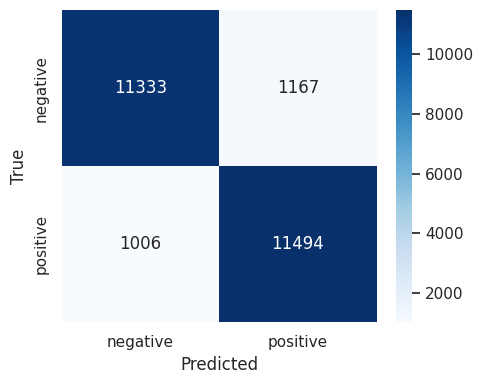

In [32]:
# Lock the validation-only choice before touching test labels.
ALLOWED_FINAL_MODELS = {
    *SCRATCH_MODEL_FACTORIES.keys(),
    "distilbert_frozen_cls",
    "distilbert_frozen_mean",
    "distilbert_finetuned",
}
FINAL_MODEL_CHOICE_PATH = RESULTS_DIR / "final_model_choice.json"

if FINAL_MODEL_CHOICE_PATH.exists():
    final_model_choice = load_json(FINAL_MODEL_CHOICE_PATH)
else:
    selection_table = comparison_summary.sort_values(
        ["mean_val_accuracy", "mean_val_cross_entropy", "model"],
        ascending=[False, True, True],
    )
    selected_row = selection_table.iloc[0]
    final_model_choice = {
        "model": selected_row["model"],
        "selection_metric": "mean validation accuracy",
        "mean_val_accuracy": float(selected_row["mean_val_accuracy"]),
        "tie_breaker": "mean validation cross-entropy",
        "mean_val_cross_entropy": float(
            selected_row["mean_val_cross_entropy"]
        ),
    }
    save_json(FINAL_MODEL_CHOICE_PATH, final_model_choice)

FINAL_MODEL_NAME = final_model_choice["model"]
assert FINAL_MODEL_NAME in ALLOWED_FINAL_MODELS
print("Final model selected from validation results:", FINAL_MODEL_NAME)
display(pd.Series(final_model_choice, name="selection record"))

FINAL_TEST_RESULT_PATH = RESULTS_DIR / "final_test_evaluation.json"
FINAL_TEST_PROBABILITIES_PATH = (
    RESULTS_DIR / "final_test_probabilities.npy"
)

if FINAL_TEST_RESULT_PATH.exists():
    final_test_result = load_json(FINAL_TEST_RESULT_PATH)
    assert final_test_result["model"] == FINAL_MODEL_NAME, (
        "A different final model has already been evaluated on the test set. "
        "Do not use test results to revise the choice."
    )
    if not FINAL_TEST_PROBABILITIES_PATH.exists():
        raise FileNotFoundError(
            "The saved test summary exists but its probabilities are missing. "
            "Restore both files from the same run."
        )
    final_test_probabilities = np.load(FINAL_TEST_PROBABILITIES_PATH)
else:
    final_test_probabilities = predict_proba_texts(
        FINAL_MODEL_NAME, test_texts
    )
    final_test_predictions = final_test_probabilities.argmax(axis=1)
    precision, recall, f1, support = precision_recall_fscore_support(
        test_labels,
        final_test_predictions,
        labels=[0, 1],
        zero_division=0,
    )
    final_test_result = {
        "model": FINAL_MODEL_NAME,
        "accuracy": accuracy_score(
            test_labels, final_test_predictions
        ),
        "confusion_matrix": confusion_matrix(
            test_labels, final_test_predictions, labels=[0, 1]
        ).tolist(),
        "per_class": {
            str(class_id): {
                "precision": precision[class_id],
                "recall": recall[class_id],
                "f1": f1[class_id],
                "support": int(support[class_id]),
            }
            for class_id in (0, 1)
        },
    }
    np.save(FINAL_TEST_PROBABILITIES_PATH, final_test_probabilities)
    save_json(FINAL_TEST_RESULT_PATH, final_test_result)

final_test_predictions = final_test_probabilities.argmax(axis=1)
display(pd.Series(final_test_result))
print(
    classification_report(
        test_labels,
        final_test_predictions,
        target_names=["negative", "positive"],
        digits=4,
    )
)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(test_labels, final_test_predictions),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["negative", "positive"],
    yticklabels=["negative", "positive"],
    ax=ax,
)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "final_test_confusion_matrix.png", dpi=180)
plt.show()


In [33]:
selected_validation_accuracy = float(
    comparison_summary.loc[
        comparison_summary["model"] == FINAL_MODEL_NAME,
        "mean_val_accuracy",
    ].iloc[0]
)
display(
    pd.DataFrame(
        {
            "split": ["validation", "test"],
            "accuracy": [
                selected_validation_accuracy,
                final_test_result["accuracy"],
            ],
        }
    )
)

length_analysis = pd.DataFrame(
    {
        "length": test_token_lengths,
        "true": test_labels,
        "predicted": final_test_predictions,
        "truncated": test_token_lengths > MAX_LEN,
    }
)
length_analysis["quartile"] = pd.qcut(
    length_analysis["length"],
    q=4,
    labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"],
)

quartile_accuracy = (
    length_analysis.groupby("quartile", observed=True)
    .apply(
        lambda group: pd.Series(
            {
                "reviews": len(group),
                "min_length": group["length"].min(),
                "max_length": group["length"].max(),
                "accuracy": np.mean(
                    group["true"] == group["predicted"]
                ),
            }
        ),
    )
    .reset_index()
)
truncation_accuracy = (
    length_analysis.groupby("truncated")
    .apply(
        lambda group: pd.Series(
            {
                "reviews": len(group),
                "accuracy": np.mean(
                    group["true"] == group["predicted"]
                ),
            }
        ),
    )
    .reset_index()
)
display(quartile_accuracy)
display(truncation_accuracy)

confidence = final_test_probabilities.max(axis=1)
incorrect_indices = np.flatnonzero(
    final_test_predictions != test_labels
)
most_confident_errors = incorrect_indices[
    np.argsort(confidence[incorrect_indices])[::-1][:6]
]
for rank, index in enumerate(most_confident_errors, start=1):
    print(
        f"\nError {rank}: index={index}, true={test_labels[index]}, "
        f"predicted={final_test_predictions[index]}, "
        f"confidence={confidence[index]:.4f}"
    )
    print(test_texts[index])


,split,accuracy
0,validation,0.92000
1,test,0.91308


/tmp/ipykernel_449/3037927047.py:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(
/tmp/ipykernel_449/3037927047.py:51: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,quartile,reviews,min_length,max_length,accuracy
0,Q1 shortest,6277.0,10.0,159.0,0.934364
1,Q2,6259.0,160.0,219.0,0.936571
2,Q3,6214.0,220.0,352.0,0.918249
3,Q4 longest,6250.0,353.0,2875.0,0.863040


,truncated,reviews,accuracy
0,False,14973.0,0.933614
1,True,10027.0,0.882417



Error 1: index=12061, true=0, predicted=1, confidence=0.9954
This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it about 20 times since I bought it a few months ago. The acting is great, although Ricki Lake could have been better. And Johnny Depp is magnificent. He is such a beautiful man and a very talented actor. And seeing most of Johnny's movies, this is probably my favorite. I give it 9.5/10. Rent it today!

Error 2: index=7109, true=0, predicted=1, confidence=0.9952
This has to be one of, if not THE greatest Mob/Crime films of all time. Every thing about this movie is great, the acting in this film is of true quality; Master P's acting skills make you actually believe he is Italian! The cinematography is excellent too, probably the best ever. This movie was great; and I have the brain capacity of an earth worm.

Error 3: index=11707, true=0, predicted=1, confidence=0.9950
This has to be one of the all time greatest hor

In [34]:
def predict(text: str) -> float:
    """Return the final model's probability that a review is positive."""
    return float(
        predict_proba_texts(FINAL_MODEL_NAME, [text])[0, 1]
    )


written_reviews = {
    "clearly positive": (
        "A moving, beautifully acted film with a confident script and a "
        "wonderful ending. I loved every minute."
    ),
    "clearly negative": (
        "This movie is painfully dull, badly acted, and far too long. "
        "I regret watching it."
    ),
    "negation": "It is not bad at all; in fact, I enjoyed it.",
    "contrast": (
        "The cast is great, but the story is incoherent and the ending "
        "ruins the entire film."
    ),
    "sarcasm": (
        "What a masterpiece: two hours of staring at a wall would have "
        "been more exciting."
    ),
    "Portuguese": (
        "O filme é excelente, emocionante e muito bem dirigido. "
        "Eu assistiria novamente."
    ),
}
probe_results = pd.DataFrame(
    {
        "case": list(written_reviews),
        "text": list(written_reviews.values()),
        "positive_probability": [
            predict(text) for text in written_reviews.values()
        ],
    }
)
display(probe_results)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,case,text,positive_probability
0,clearly positive,"A moving, beautifully acted film with a confid...",0.994998
1,clearly negative,"This movie is painfully dull, badly acted, and...",0.006931
2,negation,"It is not bad at all; in fact, I enjoyed it.",0.946001
3,contrast,"The cast is great, but the story is incoherent...",0.013046
4,sarcasm,What a masterpiece: two hours of staring at a ...,0.982389
5,Portuguese,"O filme é excelente, emocionante e muito bem d...",0.755997


### 22. Test and length-based interpretation

The final discussion will compare validation and test accuracy with the prediction made in Topic 10. Quartile and truncation results will show whether performance decreases for longer reviews or for reviews whose ending was removed.

### 23. Confident errors and written probes

The six most confident errors will be inspected for negation, sarcasm, misleading plot vocabulary, and missing context. The written probes test the same weaknesses directly, while the Portuguese example also checks behavior outside the English pretraining distribution.


## 7. What does the model use?

### Word-order test


In [36]:
# Word-order intervention across the six required model families
import unicodedata

ANALYSIS_MODELS = [
    "bag",
    "lstm",
    "transformer",
    "transformer_nope",
    "distilbert_frozen",
    "distilbert_finetuned",
]

nontruncated_val_positions = np.flatnonzero(
    train_token_lengths[idx_val] <= MAX_LEN
)
word_order_indices = idx_val[nontruncated_val_positions]
word_order_texts = [texts[index] for index in word_order_indices]
word_order_labels = labels[word_order_indices]


def tokenizer_whitespace_words(text: str) -> list[str]:
    """Split words using the same whitespace definition as the tokenizer."""
    normalized = "".join(
        " "
        if character in " \t\n\r"
        or unicodedata.category(character) == "Zs"
        else character
        for character in text
    )
    return [word for word in normalized.split(" ") if word]

shuffle_rng = np.random.default_rng(SEED)
shuffled_word_order_texts = []
for review in word_order_texts:
    words = tokenizer_whitespace_words(review)
    shuffled = shuffle_rng.permutation(words)
    shuffled_word_order_texts.append(" ".join(shuffled))

# Tokenize once for every model and verify that shuffling preserved the
# token multiset after excluding the fixed CLS and SEP tokens.
word_order_ids = batched_tokenize(
    word_order_texts, max_length=MAX_LEN, truncation=True
)
shuffled_word_order_ids = batched_tokenize(
    shuffled_word_order_texts, max_length=MAX_LEN, truncation=True
)
token_multisets_match = all(
    sorted(original_ids[1:-1]) == sorted(shuffled_ids[1:-1])
    for original_ids, shuffled_ids in zip(
        word_order_ids, shuffled_word_order_ids
    )
)
assert token_multisets_match, (
    "Whitespace shuffling changed at least one token multiset."
)

word_order_rows = []
word_order_predictions: dict[str, dict[str, np.ndarray]] = {}
for model_name in ANALYSIS_MODELS:
    original_probabilities = predict_proba_ids(
        model_name, word_order_ids
    )
    shuffled_probabilities = predict_proba_ids(
        model_name, shuffled_word_order_ids
    )
    original_predictions = original_probabilities.argmax(axis=1)
    shuffled_predictions = shuffled_probabilities.argmax(axis=1)
    word_order_predictions[model_name] = {
        "original": original_predictions,
        "shuffled": shuffled_predictions,
        "original_probabilities": original_probabilities,
        "shuffled_probabilities": shuffled_probabilities,
    }
    word_order_rows.append(
        {
            "model": model_name,
            "reviews": len(word_order_labels),
            "original_accuracy": accuracy_score(
                word_order_labels, original_predictions
            ),
            "shuffled_accuracy": accuracy_score(
                word_order_labels, shuffled_predictions
            ),
            "prediction_change_fraction": np.mean(
                original_predictions != shuffled_predictions
            ),
        }
    )

word_order_results = pd.DataFrame(word_order_rows)
display(word_order_results)
bag_probability_difference = np.max(
    np.abs(
        word_order_predictions["bag"]["original_probabilities"]
        - word_order_predictions["bag"]["shuffled_probabilities"]
    )
)
print("Maximum bag probability difference:", bag_probability_difference)
assert bag_probability_difference < 1e-5, (
    "Bag-of-embeddings probabilities changed beyond floating-point "
    "rounding; inspect the shuffle pipeline."
)
save_json(
    RESULTS_DIR / "word_order_results.json",
    word_order_results.to_dict("records"),
)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,model,reviews,original_accuracy,shuffled_accuracy,prediction_change_fraction
0,bag,1493,0.892163,0.892163,0.000000
1,lstm,1493,0.886805,0.851976,0.095111
2,transformer,1493,0.879437,0.872739,0.052244
3,transformer_nope,1493,0.880107,0.880107,0.000000
4,distilbert_frozen,1493,0.890824,0.802411,0.155392
5,distilbert_finetuned,1493,0.935700,0.821835,0.162090


Maximum bag probability difference: 1.1920929e-07


### Contrast set


In [37]:
# Contrast-set evaluation and consistency analysis
CONTRAST_BASE = (
    "https://raw.githubusercontent.com/allenai/contrast-sets/"
    "main/IMDb/data/"
)
contrast_original = pd.read_csv(
    CONTRAST_BASE + "test_original.tsv", sep="\t"
)
contrast_edited = pd.read_csv(
    CONTRAST_BASE + "test_contrast.tsv", sep="\t"
)
assert len(contrast_original) == len(contrast_edited) == 488

original_contrast_texts = [
    clean(text) for text in contrast_original["Text"].tolist()
]
edited_contrast_texts = [
    clean(text) for text in contrast_edited["Text"].tolist()
]
sentiment_to_label = {"Negative": 0, "Positive": 1}
original_contrast_labels = (
    contrast_original["Sentiment"].map(sentiment_to_label).to_numpy()
)
edited_contrast_labels = (
    contrast_edited["Sentiment"].map(sentiment_to_label).to_numpy()
)
assert np.all(original_contrast_labels != edited_contrast_labels)

test_text_set = set(test_texts)
training_text_set = {texts[index] for index in idx_train}
exact_test_matches = sum(
    text in test_text_set for text in original_contrast_texts
)
training_matches = sum(
    text in training_text_set for text in original_contrast_texts
)
print("Exact matches in official test set:", exact_test_matches)
print("Matches in assignment training split:", training_matches)
assert training_matches == 0


def wilson_interval(
    correct: int, total: int, z: float = 1.959963984540054
) -> tuple[float, float]:
    """Return a two-sided 95% Wilson confidence interval."""
    proportion = correct / total
    denominator = 1 + z**2 / total
    center = (
        proportion + z**2 / (2 * total)
    ) / denominator
    radius = (
        z
        * math.sqrt(
            proportion * (1 - proportion) / total
            + z**2 / (4 * total**2)
        )
        / denominator
    )
    return center - radius, center + radius


contrast_rows = []
contrast_predictions: dict[str, dict[str, np.ndarray]] = {}
for model_name in ANALYSIS_MODELS:
    original_predictions = predict_proba_texts(
        model_name, original_contrast_texts
    ).argmax(axis=1)
    edited_predictions = predict_proba_texts(
        model_name, edited_contrast_texts
    ).argmax(axis=1)
    contrast_predictions[model_name] = {
        "original": original_predictions,
        "edited": edited_predictions,
    }

    original_correct = original_predictions == original_contrast_labels
    edited_correct = edited_predictions == edited_contrast_labels
    original_ci = wilson_interval(
        int(original_correct.sum()), len(original_correct)
    )
    edited_ci = wilson_interval(
        int(edited_correct.sum()), len(edited_correct)
    )
    contrast_rows.append(
        {
            "model": model_name,
            "original_accuracy": original_correct.mean(),
            "original_ci_low": original_ci[0],
            "original_ci_high": original_ci[1],
            "edited_accuracy": edited_correct.mean(),
            "edited_ci_low": edited_ci[0],
            "edited_ci_high": edited_ci[1],
            "consistency": np.mean(original_correct & edited_correct),
        }
    )

contrast_results = pd.DataFrame(contrast_rows)
display(contrast_results)
save_json(
    RESULTS_DIR / "contrast_set_results.json",
    contrast_results.to_dict("records"),
)

if FINAL_MODEL_NAME in contrast_predictions:
    final_original_predictions = contrast_predictions[
        FINAL_MODEL_NAME
    ]["original"]
    final_edited_predictions = contrast_predictions[
        FINAL_MODEL_NAME
    ]["edited"]
else:
    final_original_predictions = predict_proba_texts(
        FINAL_MODEL_NAME, original_contrast_texts
    ).argmax(axis=1)
    final_edited_predictions = predict_proba_texts(
        FINAL_MODEL_NAME, edited_contrast_texts
    ).argmax(axis=1)

display_candidates = np.flatnonzero(
    (final_original_predictions == original_contrast_labels)
    & (final_edited_predictions != edited_contrast_labels)
)[:3]
for index in display_candidates:
    print(f"\nPair {index}")
    print(
        "Original:",
        contrast_original.iloc[index]["Sentiment"],
        original_contrast_texts[index],
    )
    print(
        "Edited:",
        contrast_edited.iloc[index]["Sentiment"],
        edited_contrast_texts[index],
    )


Exact matches in official test set: 1
Matches in assignment training split: 431


AssertionError: 

### 24. Word-order test

The bag model should remain unchanged after shuffling because masked averaging is permutation-invariant. Larger changes for the LSTM and positional Transformers would show that they use word order, although the change in accuracy will determine how important that information is on IMDb.

### 25. Contrast-set interpretation

The contrast set tests whether small meaning-changing edits alter the prediction correctly. Lower edited accuracy or consistency would indicate reliance on broad lexical cues rather than the specific phrase changed by the edit; the three displayed pairs will identify the failed changes directly.

### Attention and deletion test


In [ ]:
# Select the strongest Transformer-based model for attention analysis.
transformer_candidates = [
    "transformer",
    "transformer_nope",
    "transformer_max128",
]
transformer_validation_means = (
    scratch_results[
        scratch_results["model"].isin(transformer_candidates)
    ]
    .groupby("model")["best_val_accuracy"]
    .mean()
)
BEST_SCRATCH_TRANSFORMER = transformer_validation_means.idxmax()

if (
    FINAL_MODEL_NAME.startswith("transformer")
    or FINAL_MODEL_NAME.startswith("distilbert")
):
    ATTENTION_MODEL_NAME = FINAL_MODEL_NAME
else:
    ATTENTION_MODEL_NAME = BEST_SCRATCH_TRANSFORMER

print("Attention/deletion model:", ATTENTION_MODEL_NAME)


def load_attention_model(model_name: str) -> dict[str, Any]:
    """Load a Transformer with attention output enabled."""
    if model_name == "distilbert_finetuned":
        return {
            "kind": "hf",
            "model": AutoModelForSequenceClassification.from_pretrained(
                FINETUNE_DIR,
                attn_implementation="eager",
            ).to(DEVICE).eval(),
        }
    if model_name.startswith("distilbert_frozen"):
        return {
            "kind": "hf",
            "model": AutoModel.from_pretrained(
                TOKENIZER_NAME,
                attn_implementation="eager",
            ).to(DEVICE).eval(),
        }
    if model_name.startswith("transformer"):
        loaded = load_inference_model(model_name)
        return {"kind": "scratch", "model": loaded["model"]}
    raise ValueError(
        "Attention analysis requires a Transformer-based model."
    )


ATTENTION_MODEL = load_attention_model(ATTENTION_MODEL_NAME)


@torch.no_grad()
def cls_attention_for_ids(
    encoded_ids: Sequence[Sequence[int]],
    batch_size: int = 32,
) -> list[np.ndarray]:
    """Return last-layer head-averaged CLS attention."""
    dummy_targets = np.zeros(len(encoded_ids), dtype=np.int64)
    loader = DataLoader(
        ReviewDataset(encoded_ids, dummy_targets),
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_reviews,
        num_workers=0,
    )
    all_scores: list[np.ndarray] = []

    for cpu_batch in loader:
        input_ids = cpu_batch["input_ids"].to(DEVICE)
        attention_mask = cpu_batch["attention_mask"].to(DEVICE)
        lengths = cpu_batch["lengths"].numpy()

        if ATTENTION_MODEL["kind"] == "hf":
            output = ATTENTION_MODEL["model"](
                input_ids=input_ids,
                attention_mask=attention_mask,
                output_attentions=True,
            )
            scores = output.attentions[-1][:, :, 0, :].mean(dim=1)
        else:
            model = ATTENTION_MODEL["model"]
            encoder_input = model.encoder_input(input_ids)
            maps = attention_maps(
                model.encoder,
                encoder_input,
                key_padding_mask=~attention_mask.bool(),
            )
            scores = maps[-1][:, :, 0, :].mean(dim=1)

        scores = scores.float().cpu().numpy()
        all_scores.extend(
            scores[row, : int(length)]
            for row, length in enumerate(lengths)
        )
    return all_scores


def attention_html(ids: Sequence[int], scores: np.ndarray) -> HTML:
    """Render tokens with intensity proportional to attention."""
    tokens = tokenizer.convert_ids_to_tokens(list(ids))
    maximum = max(float(np.max(scores)), 1e-12)
    pieces = []
    for token, score in zip(tokens, scores):
        intensity = min(1.0, float(score) / maximum)
        pieces.append(
            "<span style='background-color: "
            f"rgba(255, 120, 0, {0.08 + 0.82 * intensity:.3f}); "
            "padding: 2px 3px; margin: 1px; display: inline-block'>"
            f"{html.escape(token)}</span>"
        )
    return HTML(" ".join(pieces))


attention_max_length = inference_max_length(ATTENTION_MODEL_NAME)
eligible_val_indices = idx_val[
    train_token_lengths[idx_val] <= attention_max_length
]
eligible_val_texts = [texts[index] for index in eligible_val_indices]
eligible_val_labels = labels[eligible_val_indices]
eligible_probabilities = predict_proba_texts(
    ATTENTION_MODEL_NAME, eligible_val_texts
)
eligible_predictions = eligible_probabilities.argmax(axis=1)
correct_positions = np.flatnonzero(
    eligible_predictions == eligible_val_labels
)
attention_example_positions = correct_positions[:3]
attention_example_texts = [
    eligible_val_texts[position]
    for position in attention_example_positions
]
attention_example_ids = batched_tokenize(
    attention_example_texts,
    max_length=attention_max_length,
    truncation=True,
)
attention_example_scores = cls_attention_for_ids(
    attention_example_ids
)

for text, ids, scores in zip(
    attention_example_texts,
    attention_example_ids,
    attention_example_scores,
):
    print("\nReview:", text[:500])
    display(attention_html(ids, scores))


In [ ]:
# Compare attention-based deletion with random deletion.
DELETION_SAMPLE_SIZE = 200
deletion_rng = np.random.default_rng(SEED)

long_enough_correct_positions = np.array(
    [
        position
        for position in correct_positions
        if len(
            tokenizer(
                eligible_val_texts[position],
                truncation=False,
                add_special_tokens=True,
            )["input_ids"]
        )
        >= 12
    ]
)
selected_positions = deletion_rng.choice(
    long_enough_correct_positions,
    size=DELETION_SAMPLE_SIZE,
    replace=False,
)
deletion_texts = [
    eligible_val_texts[position] for position in selected_positions
]
deletion_ids = batched_tokenize(
    deletion_texts,
    max_length=attention_max_length,
    truncation=True,
)
deletion_attention = cls_attention_for_ids(deletion_ids)


def delete_token_positions(
    ids: Sequence[int], positions: Sequence[int]
) -> list[int]:
    """Remove selected positions from one token sequence."""
    removed = set(int(position) for position in positions)
    return [
        token_id
        for position, token_id in enumerate(ids)
        if position not in removed
    ]


top_deleted_ids = []
random_deleted_ids = []
for ids, scores in zip(deletion_ids, deletion_attention):
    candidate_positions = np.arange(1, len(ids) - 1)
    top_positions = candidate_positions[
        np.argsort(scores[candidate_positions])[-10:]
    ]
    random_positions = deletion_rng.choice(
        candidate_positions, size=10, replace=False
    )
    top_deleted_ids.append(delete_token_positions(ids, top_positions))
    random_deleted_ids.append(
        delete_token_positions(ids, random_positions)
    )

baseline_probabilities = predict_proba_ids(
    ATTENTION_MODEL_NAME, deletion_ids
)
top_deleted_probabilities = predict_proba_ids(
    ATTENTION_MODEL_NAME, top_deleted_ids
)
random_deleted_probabilities = predict_proba_ids(
    ATTENTION_MODEL_NAME, random_deleted_ids
)

baseline_predictions = baseline_probabilities.argmax(axis=1)
rows = np.arange(DELETION_SAMPLE_SIZE)
baseline_class_probability = baseline_probabilities[
    rows, baseline_predictions
]
top_class_probability = top_deleted_probabilities[
    rows, baseline_predictions
]
random_class_probability = random_deleted_probabilities[
    rows, baseline_predictions
]

deletion_results = pd.DataFrame(
    [
        {
            "deletion": "top attention",
            "mean_probability_decrease": np.mean(
                baseline_class_probability - top_class_probability
            ),
            "prediction_change_fraction": np.mean(
                top_deleted_probabilities.argmax(axis=1)
                != baseline_predictions
            ),
        },
        {
            "deletion": "random",
            "mean_probability_decrease": np.mean(
                baseline_class_probability - random_class_probability
            ),
            "prediction_change_fraction": np.mean(
                random_deleted_probabilities.argmax(axis=1)
                != baseline_predictions
            ),
        },
    ]
)
display(deletion_results)
save_json(
    RESULTS_DIR / "attention_deletion_results.json",
    deletion_results.to_dict("records"),
)


### 26. Attention and deletion interpretation

Attention highlights where the class token gathers information, but it does not prove that a token caused the prediction. If deleting high-attention tokens reduces confidence more than random deletion, it provides supporting evidence of importance, while still remaining an intervention on a modified input.

## 8. Conceptual questions

### TODO - Answer all eight conceptual questions using the measured results

## 9. Final discussion

The assignment compares three sources of useful sequence behaviour: recurrent memory, positional attention, and language pretraining. After execution, this section will summarize which measurements supported each claim and identify the main computational or methodological difficulties encountered.
